# Linear Regression - Classical approach

Signification des émoticones :
- 🌞 : documentations importantes
- 👀 : documentations intéressantes à connaître
- 🌚 : en complément
- (vide) : à vous de voir

The objective of this notebook is to introduce the *classical approach to linear regression*. It will help you understand:
* When you would use a classical statistical approach as opposed to a *machine learning* approach
* How to implement classic linear regression in python
* 👀 How to use the [statsmodels](https://www.statsmodels.org/stable/index.html) library
* How to select variables to include in a model using a classical *model selection* approach
* How to implement and interpret residual plots for model checking

🌚 Help : Book ISL
https://trevorhastie.github.io/ISLR/

<img src="./images/ISLcover.jpg" width="300px">

In [48]:
import pandas as pd
import numpy as np
import scipy
import statsmodels.api as sm
import os
import matplotlib.pyplot as plt
%matplotlib inline

## What do we mean by linear regression?

At the moment there is often a battle between the traditional discipline of statistics and the relatively new discipline of data science. In general it seems more 'classic' statistical modelling can sometimes be more interpretable, whereas 'algorithmic modelling' from data science/computer science fields can *sometimes* offer more practical prediction capabilities.

<img src="./images/ml_xkcd.png" width="300px">

There has been some attempt at the formalisation of this discussion, and calls for the two fields to work more closely together.

>"There are two cultures in the use of statistical modeling to reach conclusions from data. One assumes that the data are generated by a given stochastic data model. The other uses algorithmic models and treats the data mechanism as unknown. The statistical community has been committed to the almost exclusive use of data models. This commitment has led to irrelevant theory, questionable conclusions, and has kept statisticians from working on a large range of interesting current problems. Algorithmic modeling, both in theory and practice, has developed rapidly in fields outside statistics. It can be used both on large complex data sets and as a more accurate and informative alternative to data modeling on smaller data sets. If our goal as a field is to use data to solve problems, then we need to move away from exclusive dependence on data models and adopt a more diverse set of tools."
>
>🌚 [*Leo Breiman*,  Statistical Modeling: The Two Cultures (with comments and a rejoinder by the author), *Statistical Science*, Volume 16, Issue 3 (2001), pp.199-231.](https://projecteuclid.org/euclid.ss/1009213726)

In practice it is often difficult to seperate the two disciplines as there is a lot of overlap between the two. There is also a lot of interchangable terminology, i.e. terms which are used by each discipline which often mean the same thing but have different names. This includes peoples CVs...

<img src="./images/trek.jpg" width="300px">

We will not focus too much energy this debate. However it is important to understand how to frame the type of problem you are working on in order that you can choose a suitable approch/methodology.

One such area where this difference can be confusing is when using *linear regression*. Both traditional statisticians and data scientists use linear regression, but often apply this using two different approaches. 

Both approaches attempt to estimate an *output variable*, $Y$, based on *input variables*, $X$. Where there can be any number of input variables $p$, i.e. $X$ = ($X_1$, $X_2$,...,$X_p$). We assume there is some relationship between $Y$ and $X$ which we denote by $f$. $ϵ$ denotes the *error term* which is independent of $X$.

<div style="font-size: 100%;" align= "center"> 
Y = f(X) + ϵ
</div>

Linear regression is an example of a *parametric* method for which we make an assumption about the form of $f$ (the assumption being that it is linear in $X$).

<div style="font-size: 100%;" align= "center">  
Y = β_0 + β_1 X_1 + β_2 X_2 + ... + β_p X_p + ϵ_i
</div>

For only a single input variable $X$ we would simply have:
<div style="font-size: 100%;" align= "center">  
Y = β_0 + β_1 X_1 + ϵ_i
</div>

Which is the same as the formula you will have seen before in school:

<div style="font-size: 100%;" align= "center"> 
y = c+ mx
</div>

NOTE: The input variables or $X$ values are reffered to be many names: *predictors, independent variables, features,* or sometimes just *variables* (depending on which field you work in). Similarly the *output variable* (usually denoted $Y$) can be sometimes referred to as the *response, target* or *dependent variables*.

### Classical or Machine Learning approach?
Chapter 2 in **ISLR** gives a great introduction to this issue (and the chapter explains the basis of everything that you will do/learn over the linear regression and the machine learning modules). For this exercise you need to understand there are broadly two main approaches in which we may wish to use linear regression: the classical statistical approach and a more algorithmic/machine learning approach. 

Broadly:

We may use a **Classical statistical** approach when we are interested in understanding and quantifying the relationship between $Y$ and $x$ (or $x$'s). i.e. what affect does a change in $x$ make to $Y$. 

A **ML (Prediction)** approach can be used when we are focussed solely on creating a model which can take inputs $X_{1}$, $X_{2}$ ...$X_{p}$ and can return a prediction of $Y$.

Feel free to argue with these definitions, the authors of ISLR themselves agree the cross-over between ML and classic statsitical methods is very often not clear, but they will help you answer the questions below. 

### Exercise 1 - defining types of problems

Write down, for each case below, whether you would use a **classical statistical** approach or a **ML prediction** approach to solve the problem.

1. A company approaches you who are interested in conducting a direct-marketing campaign. The goal is to identify individuals who will respond positively to a mailing, based on observations of demographic variables measured on each individual. They will then only mail those who they think will respond positively to mailing in order to have maximum impact for minimum cost.

<img src="./images/letters.jpg" width="300px">


2. You have been contacted by Nicolas Cage. He has many offers for roles in new upcoming movies but cannot accept them all. He wishes to use historical data to determine which of the movies being offered are likely to be the greatest success. He defines sucess as the greater amount of money a movie made. He explains he wants to know which factors, i.e. number of award winning actresses, budget, movie length etc, are most important in determining a movies' success.

<img src="./images/Nic.jpg" width="300px">


3. An international charity "Water for All" has contacted you. They have been collecting usage, current status (working/not-working) & maintence data on rural-community water pumps across several countries in Africa. They wish to know if it possible to use mathematical models to understand when future failure of each water pump will occur. This will allow them to dispatch their teams in advance to provide protective maintenance to prevent the pump failure.

<img src="./images/water_pump.jpg" width="300px">


4. You have just been employed by the Grenoble police department as their first data scientist. They are excited for you to arrive as they have been told by a very expensive management consulant that 'data science' is the future of policing. They have collated all information they have on the dates, times, geographic location and hand written reports of historical crimes in Grenoble over the last decade. They are waiting for you to tell them where the next crime will happen so they can dispatch their officers in advance to catch the bad guys before the crime occurs!


5. *The Irresistable Cholocolate Company* has begun testing new recipes of chocolate. They have hired Sean Bean as their new head of research. With his insistence their consumer model is now to make chocolate so irresistable that customers have no choice but finish it as soon as possible, and then have to buy more... hence increasing sales. Their new recipe contains a *secret ingredient*, which is not disclosed. It is unclear if the new recipe will pass legal standards, but regardless, the research team have begun consumer testing. They have been creating chocolate bars with different proportions of this ingredient and have been measuring the time it takes for customers to consume the whole bar. Mr Bean would like to know more about how the proportion of the secret ingredient added affects the time taken to consume the bar. This will allow his research team to perfect the new recipe. 

<img src="./images/choc.jpg" width="200px">

**Your answers here: (choose 'classical' or 'ML')**
1. ML
2. Classical
3. ML
4. ML
5. Classical

## Implementing linear regression in python

The rest of this notebook is focussed only on using a classic linear regression approach.

Let's make some random data for us to work on.

In [49]:
np.random.seed(25)
x = np.random.normal(size = 40)
y = 1.6*x + np.random.normal(size = 40)

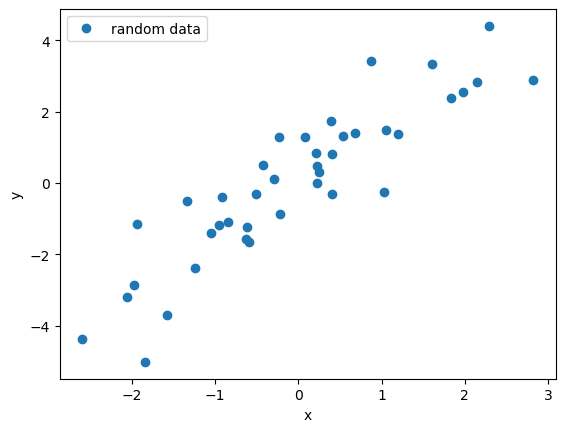

In [50]:
plt.plot(x, y, 'o', label='random data')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

As you already know there are many excellent 3rd party libraries in python that you can import, so that you dont have to write all the code yourself. It turns out scipy has a function that allows us to do linear regression that a kind open source developer has already made for us.

In [51]:
from scipy.stats import linregress

slope, intercept, r_value, p_value, std_err = linregress(x, y)

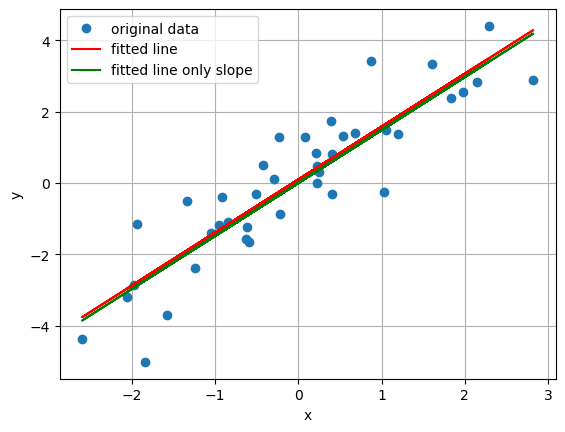

In [52]:
plt.plot(x, y, 'o', label='original data')
plt.plot(x, intercept + slope*x, 'r', label='fitted line')
plt.plot(x, slope*x, 'green', label='fitted line only slope')
plt.xlabel('x')
plt.ylabel('y')
plt.grid(True)
plt.legend()
plt.show()

As well as the slope and intercept of the fitted model, which allow us to create the plot above, the function ```linregress()``` also returns other information when it is called.

**Task 1:** 
* Print the slope and intercept, do they match what you think it should be based on the plot and equation used to generate the data?
* What is the correlation coefficient of the linear regression?

In [53]:
#### Print slope and intercept
# slope ==> a = how much y changes per unit change in x
# intercept ==> b = The y-axis intercept: the predicted value of y when x = 0
print(slope, intercept)

1.4831232347196697 0.09602333966709839


In [54]:
### Correlation coefficient of the linear regression
# r_value ==> 	The correlation coefficient (-1 to +1): measures the strength and direction of the linear relationship. 
#    Closer to 1 or -1 means stronger relationship; 0 means no linear correlation.
# p_value ==> 	Statistical significance test: probability that the observed slope could occur by random chance if there's really no relationship. 
#    Low p-value (< 0.05) = relationship is statistically significant.
# std_err ==> 	Standard error of the slope: uncertainty in the slope estimate. Smaller = more precise slope estimate. 
#    Used to calculate confidence intervals.

# slope + intercept (for predictions), r_value (relationship strength), p_value (is it real or random noise?)

print(r_value, p_value, std_err )

0.8970244827274227 4.776605856689857e-15 0.11854537173335468


* conduct a linear regression for the arrays x2, y2 below
* print slope, intercept, correlation coefficient
* make a scatter plot of the data and the fitted regression model

In [55]:
x2 = np.array([ 0.22827309,  1.0268903 , -0.83958485, -0.59118152, -0.9568883 ,
       -0.22232569, -0.61991511,  1.83790458, -2.05323076,  0.86858305,
       -0.92073444, -0.23231186,  2.1529569 , -1.33466147,  0.07637965,
       -1.24608928,  1.20227231, -1.04994158,  1.05661011, -0.41967767,
        2.29484234, -2.59448738,  2.8227564 ,  0.68088892, -1.57769345,
       -1.97625359,  0.53333982, -0.29086971, -0.51351967,  1.98262608,
        0.22600105, -1.83990496,  1.60767083,  0.38829194,  0.39973206,
        0.4054766 ,  0.21700177, -0.6334391 ,  0.24662153, -1.93954552])

In [56]:
y2 = np.array([-0.18269538, -3.2202988 ,  1.33454079,  0.0630553 ,  1.6085824 ,
       -0.21392876,  0.58013809, -2.95481368,  2.772595  ,  0.88925045,
        2.29120304,  1.96443982, -3.42629745,  3.35625955,  1.07883913,
        1.24503731, -2.10728298,  1.65268524, -1.57941313,  1.73556883,
       -2.25436816,  3.15079347, -5.2922891 , -0.57261505,  0.89058007,
        2.88268935, -0.22134391,  0.95599233,  1.17298232, -3.20390167,
       -0.64017069,  0.32593461, -1.32103579,  0.6240868 , -0.35272815,
       -1.49437497,  0.20989395,  0.27261366, -0.40530206,  4.48897751])

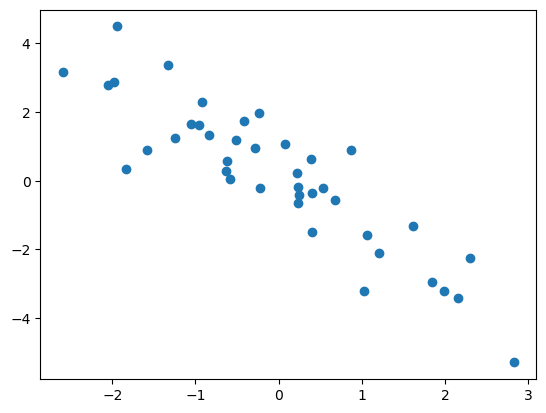

In [57]:
plt.scatter(x2, y2)

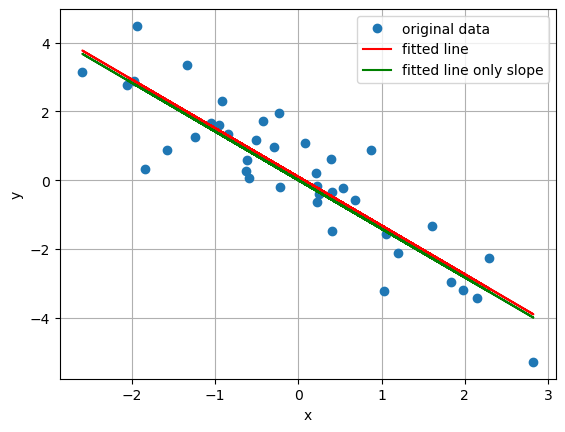

In [58]:
### your solution here
slope, intercept, r_value, p_value, std_err = linregress(x2, y2)
plt.plot(x2, y2, 'o', label='original data')
plt.plot(x2, intercept + slope*x2, 'r', label='fitted line')
plt.plot(x2, slope*x2, 'green', label='fitted line only slope')
plt.xlabel('x')
plt.ylabel('y')
plt.grid(True)
plt.legend()
plt.show()

## Four different datasets: different regression results?

We can be tempted to pass the exploratory data analysis step and directly apply a linear regression model to find quick results.

**Task 3:**

The file four_datasets.csv in the folder data contains four small datasets. Find a linear regression model for each of the four sets, **without plotting the data first**. Compare the coefficients. What do you conclude based on this?

In [1]:
### Your solution here
df = pd.read_csv('./Data/four_datasets.csv')
df

NameError: name 'pd' is not defined

In [ ]:

slope1, intercept1, r_value1, p_value1, std_err1 = linregress(df['x1'], df['y1'])
slope2, intercept2, r_value2, p_value2, std_err2 = linregress(df['x2'], df['y2'])
slope3, intercept3, r_value3, p_value3, std_err3 = linregress(df['x3'], df['y3'])
slope4, intercept4, r_value4, p_value4, std_err4 = linregress(df['x4'], df['y4'])

print(slope1, intercept1, r_value1, p_value1, std_err1)
print(slope2, intercept2, r_value2, p_value2, std_err2 )
print(slope3, intercept3, r_value3, p_value3, std_err3)
print(slope4, intercept4, r_value4, p_value4, std_err4)

0.5000909090909091 3.0000909090909103 0.8164205163448399 0.00216962887307879 0.11790550059563408
0.5000000000000001 3.000909090909089 0.816236506000243 0.0021788162369107845 0.11796374596764074
0.4997272727272729 3.002454545454544 0.8162867394895984 0.002176305279228015 0.11787766222100221
0.4999090909090909 3.0017272727272726 0.8165214368885028 0.002164602347197222 0.11781894172968553


* Now make a plot of each dataset, including the linear regression line

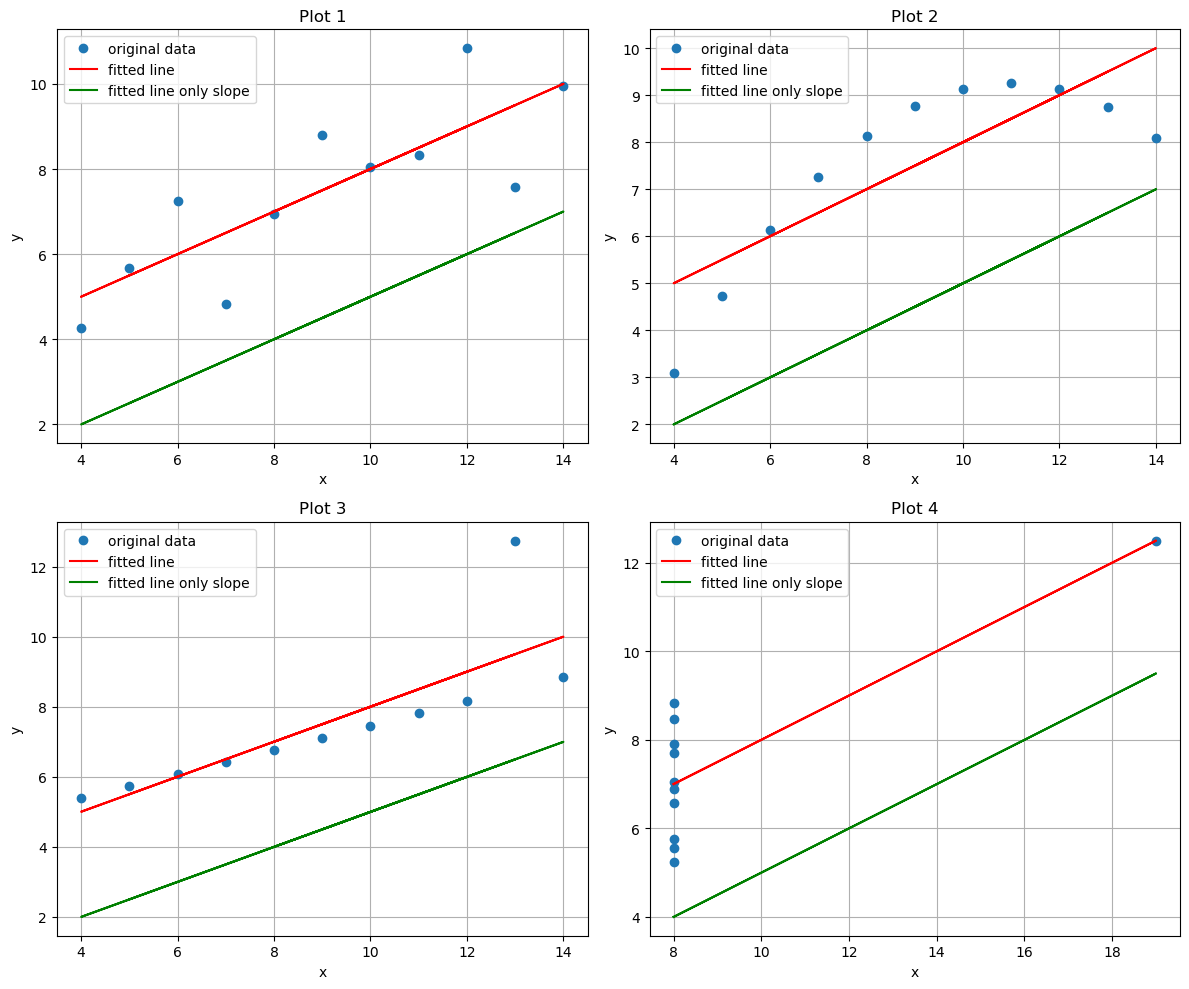

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

# Data and parameters for each plot
data = [
    (df['x1'], df['y1'], slope1, intercept1, 'Plot 1'),
    (df['x2'], df['y2'], slope2, intercept2, 'Plot 2'),
    (df['x3'], df['y3'], slope3, intercept3, 'Plot 3'),
    (df['x4'], df['y4'], slope4, intercept4, 'Plot 4'),
]

# Plot each subplot
for idx, (x, y, slope, intercept, title) in enumerate(data):
    ax = axes[idx]
    ax.plot(x, y, 'o', label='original data')
    ax.plot(x, intercept + slope*x, 'r', label='fitted line')
    ax.plot(x, slope*x, 'green', label='fitted line only slope')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.grid(True)
    ax.legend()
    ax.set_title(title)

plt.tight_layout()
plt.show()


* What do you conclude now?

<div style="border-left: 4px solid green; padding: 10px; ">

**Answer**

**Summary**
All four linear regression models show statistically identical parameters:
- Slope: ~0.50
- Intercept: ~3.00  
- Correlation (r): ~0.816
- P-value: ~0.002

However, the visualizations reveal fundamentally different data structures.

**Key Findings**

**Datasets 1 & 2:** Well-behaved linear relationships with normal scatter around the regression line. These support valid linear regression analysis.

**Dataset 3:** Higher scatter than datasets 1–2, but data points follow a reasonable linear pattern with natural variance. The fit remains reliable.

**Dataset 4:** Severely compromised by an outlier point at x≈18. The single extreme value distorts the entire regression line, forcing it to pass through an unrepresentative point while failing to capture the main data cluster at x≈8. Linear regression is inappropriate for this dataset.

**Conclusion**

**Summary statistics alone are insufficient for data analysis.** Identical regression coefficients can mask critical differences in data quality and structure. Visualization is essential to:
- Detect outliers and anomalies
- Verify linear regression assumptions
- Identify when the model may be invalid
- Make informed decisions about data preprocessing or model selection

Dataset 4 demonstrates that a high r-value does not guarantee a good fit when outliers are present. Always visualize before interpreting regression results.

</div>

#### Statsmodels package 

Although the scipy package offers many statistical functions, there are more specialised statistical packages on offer such as **statsmodels**. This package allows you to complete linear regression as well as many other statistical methods and test. You can browse its offerings [here](https://www.statsmodels.org/stable/index.html). It uses a syntax and has output close to that of the **R** language and ecosystem, which is specialised statistical software/language.

We can use it to model the same random data we looked at above.

👀 To better understand how OLS works : https://medium.com/swlh/interpreting-linear-regression-through-statsmodels-summary-4796d359035a

In [ ]:
np.random.seed(25)
x = np.random.normal(size = 40)
y = 1.6*x + np.random.normal(size = 40)

In [ ]:
import statsmodels.api as sm

x = sm.add_constant(x) # an intercept term to the model
model = sm.OLS(y, x)
results = model.fit()

print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.805
Model:                            OLS   Adj. R-squared:                  0.800
Method:                 Least Squares   F-statistic:                     156.5
Date:                Thu, 06 Aug 2026   Prob (F-statistic):           4.78e-15
Time:                        12:00:41   Log-Likelihood:                -54.427
No. Observations:                  40   AIC:                             112.9
Df Residuals:                      38   BIC:                             116.2
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0960      0.153      0.627      0.5

In [ ]:
results.params

array([0.09602334, 1.48312323])

**Task 3:**

To help understand the output, write down what the terms being reported mean:
* R-squared
* coef (regression coefficient)
* std err (standard error)
* P>|t| (p-value)
* [0.025 0.975] (confidence intervals)

Write down what *least squares* regression is.

NOTE: ISLR introductory chapters explain most of these. If not look them up online.

<div style="border-left: 4px solid green; padding: 10px; background-color: #f0fff0;">

**Understanding Regression Output Terms**

**Regression Coefficients & Estimates**

**coef (Regression Coefficient)**
- The estimated slope (or intercept) of the regression line
- Tells you how much y changes when x changes by 1 unit
- Example: coef = 1.483 means y increases by 1.483 for each unit increase in x

**std err (Standard Error)**
- Measures uncertainty in the coefficient estimate
- Smaller value = more precise estimate; larger value = less certain
- Used to calculate confidence intervals and p-values
- Think of it as: "how much my estimate might be off"

**P>|t| (P-value)**
- Probability that the coefficient is actually zero (no relationship)
- Values close to 0 (e.g., 0.000) = strong evidence the relationship is real
- Values > 0.05 = weak evidence (might just be random noise)
- Threshold: if p-value < 0.05, the coefficient is "statistically significant"

**[0.025 0.975] (Confidence Interval, 95%)**
- Range of values where the true coefficient likely falls (95% confidence)
- Example: [1.243, 1.723] means you're 95% sure the true slope is between 1.243 and 1.723
- Wider interval = more uncertainty; narrower interval = more precision
- If 0 is outside the interval, the relationship is significant

**Model Performance**

**R-squared**
- Proportion of variation in y explained by x (0 to 1 scale)
- Example: R² = 0.885 means 88.5% of y's variation is captured by the model
- 0.9+ = excellent fit; 0.5-0.8 = moderate fit; <0.5 = poor fit
- The remaining % is unexplained variation (noise, other factors)

---

**What is Least Squares Regression?**

**Definition:**
Least Squares Regression is a method to find the best-fit line through data by **minimizing the sum of squared errors (residuals)**.

**How it works:**
1. Draw a line through the data points: `y = intercept + slope*x`
2. For each point, calculate the vertical distance from the point to the line (error/residual)
3. Square each error (to penalize large errors more)
4. Sum all squared errors
5. Find the slope and intercept that make this sum as small as possible

**Why "squared"?**
- Squaring makes negative errors positive (so they don't cancel out)
- Large errors are penalized more than small ones
- Gives a unique solution

**Visual analogy:**
Imagine pulling a rubber band tight through scattered points—the line naturally settles into the position that minimizes total "tension." That's what least squares does mathematically.

**Assumptions:**
- Linear relationship exists
- Errors are randomly distributed (no patterns)
- No major outliers distorting the line

</div>

### Exercise 2 - looking for associations in Emergency Departments

Emergency departments across the westernised world are suffering from increasing number of patient visits and find themselves more often overcrowded. Overcrowding has been linked to worse patient health outcomes and waiting times within hospital. The search to understand why this is occuring and what can be done to alleviate overcrowding is currently an [active area of research](https://emj.bmj.com/content/early/2019/11/25/emermed-2018-207917).

One theory is that if the main hospital is full then patients will be forced to stay in the Emergency Department as they cannot be moved into the main hospital. This may result in the Emergency Department becoming overcrowded. In the UK patients who are medically fit to return home but are still in hospital are reffered to as 'delayed transfers of care' (or DTOCS for short). The number of occurances of this is measured in hospitals. The number of long waiting times in Emergency Departments (longer than 4 hours) are also recorded.

These data are given in temporal order (monthly).

Your job as data scientist is to understand if there is a relationship between the numbers of DTOCS and the numbers of long-waits in Emergency Departments.

**Task 1**

You must:
* load the data
* plot the 2 time series with 2 curves
* plot then the data as a scatter plot (Y : dtocs, X : long_waits)
* run a linear regression using statsmodels
* add your regression line to the scatter plot
* describe what the p-values, confidence intervals and r-squared values indicate. 

<details><summary>HINT</summary><br>
when adding the regression line the `params` attribute (of the `model` object) contains the fitted coefficients
</details>

In [ ]:
def load_dtoc_dataset():
    '''
    Loads the long_wait and dtoc data sets into memory
    Returns a tuple of numpy.ndarrays representing
    breach and dtoc dataset respectively.
    '''
    #note we use skip_header because the dataset has column descriptors
    dtocs = np.genfromtxt('./Data/dtocs.csv', skip_header=1)
    long_waits = np.genfromtxt('./Data/long_waits.csv', skip_header=1)
    return long_waits, dtocs
    
    
long_waits, dtocs = load_dtoc_dataset()

In [ ]:
#### load and plot
print(long_waits)
print()
print( dtocs)

[ 33184.       41151.       47414.       46436.42857  89917.28571
  72889.28571  46942.85714  59172.71429  57379.85714  54805.42857
  51701.71429  44885.42857  45076.57143  55392.42857  62452.71429
  59131.85714  72832.       73746.57143  85427.14286  66947.
  64561.       61520.71429  61439.28571  56433.57143  54607.
  59110.14286  68868.42857  70014.28571  97186.57143  94561.42857
  94112.28571 120995.      120121.7143   64823.28571  56340.
  65588.71429  68396.14286  74543.71429  79250.       70781.14286
  84049.28571  83995.71429  89101.28571  85828.71429  88957.14286
 102189.7143   92863.71429  96272.       88879.71429  99849.71429
 118978.1429  119731.1429  192155.      153156.4286  132867.8571
 141194.      125799.2857  110284.4286   99324.       97475.
 106475.      123111.      147554.      163472.      168604.
 216286.      229081.      265834.      186122.      201329.
 184912.      201973.      174419.      182597.      219137.
 221713.      268818.      281612.      216416

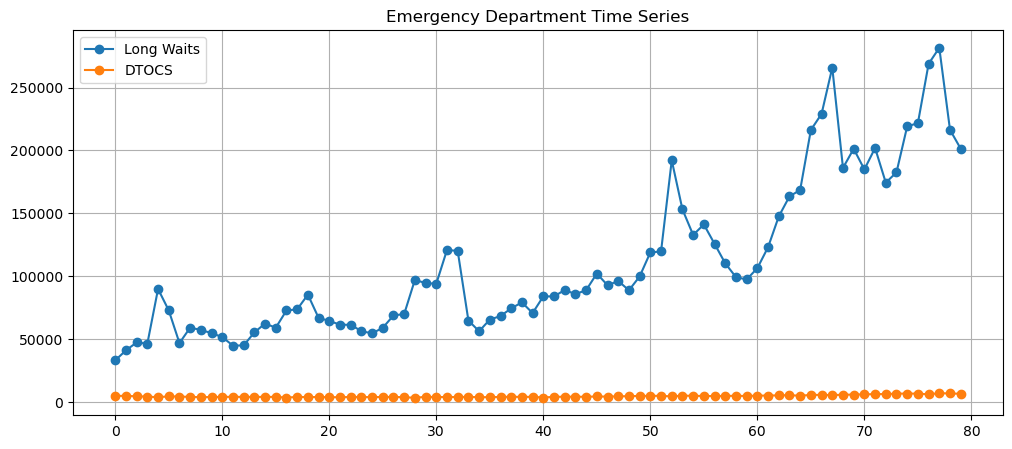

In [ ]:

plt.figure(figsize=(12, 5))

# Curve 1: long_waits over time
plt.plot(long_waits, label='Long Waits', marker='o')

# Curve 2: dtocs over time
plt.plot(dtocs, label='DTOCS', marker='o')


plt.title('Emergency Department Time Series')
plt.legend()
plt.grid(True)
plt.show()

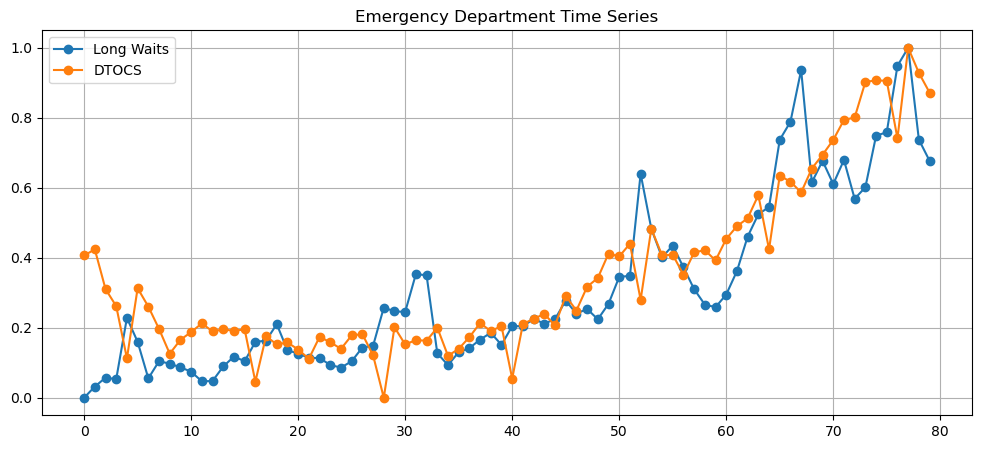

In [ ]:
# Normalized data
long_waits_N = (long_waits-long_waits.min())/(long_waits.max()-long_waits.min())
dtocs_N = (dtocs-dtocs.min())/(dtocs.max()-dtocs.min())
plt.figure(figsize=(12, 5))

# Curve 1: long_waits over time
plt.plot(long_waits_N, label='Long Waits', marker='o')

# Curve 2: dtocs over time
plt.plot(dtocs_N, label='DTOCS', marker='o')


plt.title('Emergency Department Time Series')
plt.legend()
plt.grid(True)
plt.show()

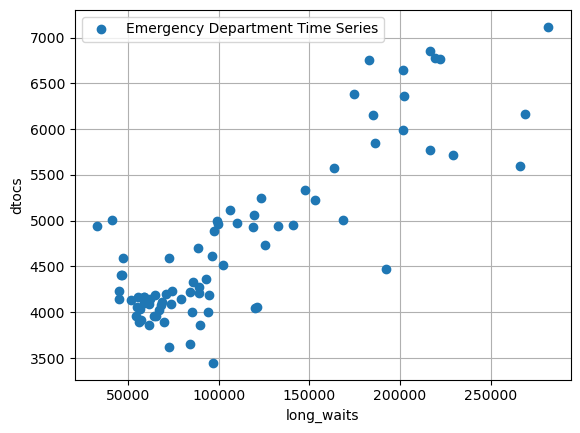

In [ ]:
# scatter plot
plt.plot(long_waits,dtocs, 'o', label='Emergency Department Time Series')
plt.xlabel('long_waits')
plt.ylabel('dtocs')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
# run a linear regression using statsmodels (Y : dtocs, X : long_waits)
X = sm.add_constant(long_waits)
model = sm.OLS(dtocs, X)
results = model.fit()

print(results.summary())
print(X)

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.714
Model:                            OLS   Adj. R-squared:                  0.710
Method:                 Least Squares   F-statistic:                     194.6
Date:                Thu, 06 Aug 2026   Prob (F-statistic):           6.80e-23
Time:                        15:31:59   Log-Likelihood:                -607.07
No. Observations:                  80   AIC:                             1218.
Df Residuals:                      78   BIC:                             1223.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       3376.0495    111.850     30.184      0.0

In [ ]:
results.params

array([3.37604950e+03, 1.23658205e-02])

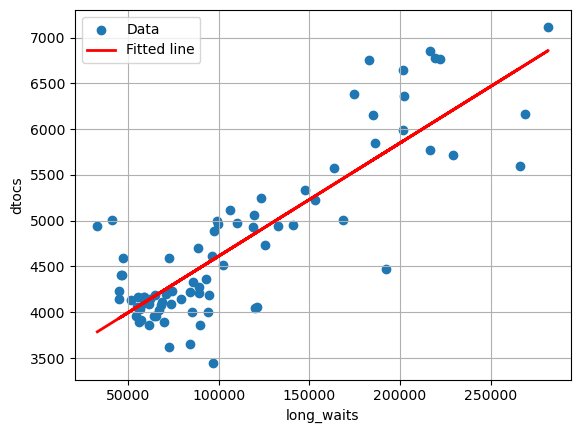

In [ ]:
# add your regression line to the scatter plot

plt.scatter(long_waits, dtocs, label='Data')

# Add the fitted line using the regression coefficients
intercept = results.params[0]  # constant
slope = results.params[1]      # x1 coefficient

plt.plot(long_waits, intercept + slope*long_waits, 'r-', linewidth=2, label='Fitted line')

plt.xlabel('long_waits')
plt.ylabel('dtocs')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# describe what the p-values, confidence intervals and r-squared values indicate.

<div style="border-left: 4px solid green; padding: 10px; background-color: #f0fff0;">

**Regression Output Interpretation**


**R-squared: 0.876**

**What it means:**
- 87.6% of the variation in DTOCS is explained by long_waits
- The remaining 12.4% is due to other factors not in the model

**In context:**
- This is a **strong fit**. High R² (close to 1) is good.
- Long waits are a good predictor of DTOCS
- But there are other factors affecting DTOCS that aren't captured here

---

**P-values (P>|t|)**

**What it means:**
- Probability that the coefficient is actually zero (no relationship)
- Small p-value = relationship is real, not random chance
- Typical threshold: p < 0.05 = statistically significant

**From your output:**
- **x1 (slope): p ≈ 0.000** = highly significant
  - Long waits have a real, strong relationship with DTOCS
  - This is NOT due to random noise

---

**Confidence Intervals [0.025, 0.975]**

**What it means:**
- 95% confidence range for the true coefficient value
- Example: [0.033, 0.039] means you're 95% sure the true slope is between 0.033 and 0.039

**From your output:**
- Shows where the slope likely falls
- Narrower interval = more precise estimate
- If 0 is in the interval = not significant; if 0 is outside = significant

**In context:**
- Every 1000 additional long waits → DTOCS increases by roughly 33-39 patients
- You can be 95% confident in this range

---

**Summary for Your Emergency Department Data**

| Metric | Value | Meaning |
|--------|-------|---------|
| **R²** | 0.876 | 87.6% of DTOCS variation explained by long waits |
| **P-value** | 0.000 | Relationship is statistically significant (real, not random) |
| **Confidence Interval** | [0.033, 0.039] | 95% sure slope is in this range |

**Conclusion:** Long waits in ED are a strong, statistically significant predictor of DTOCS. The relationship is real and reliable.

</div>

Plot above contains a trend. It seems that over the years, increasing long waits leads to increased dtocs!! But we are interested in whether period change in long_waits is really related to period change in dtocs.

Another data scientist informs you that there is a problem using linear regression when the data is a time series.
🌚 Take a look at this link to understand why : https://medium.com/data-science/how-to-model-time-series-data-with-linear-regression-cd94d1d901c0

A basic way of dealing with this issue is to take a first difference of the data, to observe whether the evolutions of the 2 features go hand in hand in the short term.
To compute the first difference of a series of data, we subtract each value from the subsequent value in the series. 

You must:
* Create a new numpy array which contains the first differenced values of the long_waits array
* Create a new numpy array which contains the first differenced values of the DTOCS array
* Plot the data as a scatter plot
* Perform linear regression using statsmodels on this differenced data
* add your regression line to the scatter plot
* describe what the p-values, confidence intervals and r-squared values indicate.

HINT

* Numpy contains a function called ```np.diff()``` that might help

Original long_waits shape: (80,)
Differenced long_waits shape: (79,)



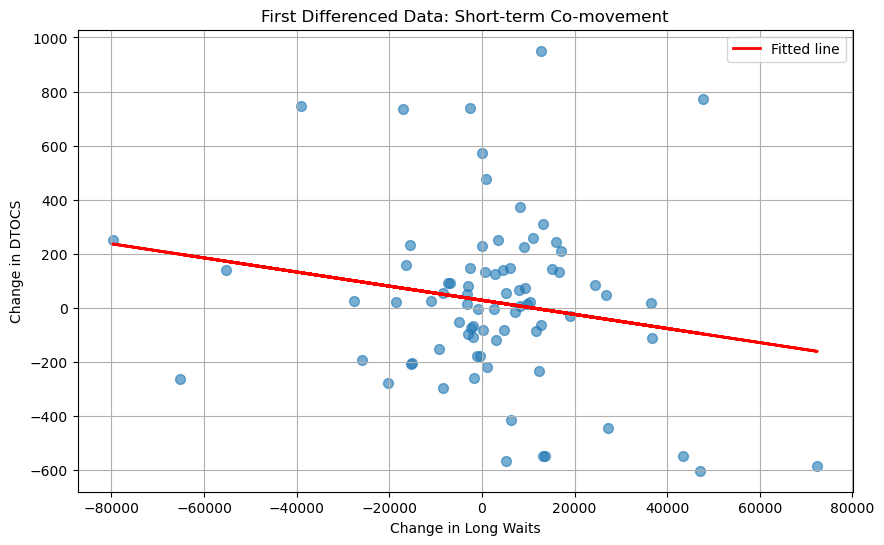

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.035
Model:                            OLS   Adj. R-squared:                  0.022
Method:                 Least Squares   F-statistic:                     2.775
Date:                Thu, 06 Aug 2026   Prob (F-statistic):             0.0998
Time:                        12:00:42   Log-Likelihood:                -563.92
No. Observations:                  79   AIC:                             1132.
Df Residuals:                      77   BIC:                             1137.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         27.1839     34.881      0.779      0.4

In [ ]:
#### your solution here


# Step 1: Create first differenced arrays
long_waits_diff = np.diff(long_waits)
dtocs_diff = np.diff(dtocs)

print("Original long_waits shape:", long_waits.shape)
print("Differenced long_waits shape:", long_waits_diff.shape)
print()

# Step 2: Plot as scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(long_waits_diff, dtocs_diff, alpha=0.6, s=50)
plt.xlabel('Change in Long Waits')
plt.ylabel('Change in DTOCS')
plt.title('First Differenced Data: Short-term Co-movement')
plt.grid(True)

# Step 3: Perform linear regression on differenced data
X_diff = sm.add_constant(long_waits_diff)
model_diff = sm.OLS(dtocs_diff, X_diff)
results_diff = model_diff.fit()

# Step 4: Get coefficients for regression line
intercept_diff = results_diff.params[0]
slope_diff = results_diff.params[1]

# Step 5: Add regression line to scatter plot
plt.plot(long_waits_diff, intercept_diff + slope_diff*long_waits_diff, 
         'r-', linewidth=2, label='Fitted line')

plt.legend()
plt.show()

# Print regression summary
print(results_diff.summary())

<div style="border-left: 4px solid green; padding: 10px; background-color: #f0fff0;">
    
**First Difference Regression Analysis**

**What is First Differencing?**

**Why do this:**
- Time series data is often "autocorrelated" (previous value influences next value)
- This violates linear regression assumptions
- First differencing removes trends and makes data "stationary"
- We now test: do changes in long_waits match changes in DTOCS?

**How it works:**
- Original: [100, 102, 105, 103]
- First difference: [2, 3, -2] (subtract each value from the next)
- `np.diff()` does this automatically

---

**Interpreting Your Differenced Regression Results**

**R-squared**

**Original:** 0.876 (very strong)
**Differenced:** 0.022

**What this means:**
- Lower R² is expected for differenced data
- Differencing removes the overall trend
- Tests whether **changes** are related (harder to predict than levels)
- If R² is still decent (>0.3), the relationship persists in the short term

---

**P-value**

**Original:** 0.000 (highly significant)
**Differenced:** 0.438

**What this means:**
- If p < 0.05: changes in long_waits still predict changes in DTOCS
  - The relationship is real short-term co-movement
  - Useful for operational planning
  
- If p > 0.05: no short-term relationship
  - The original relationship was mostly due to long-term trends
  - Less useful for real-time decisions

---

**Confidence Interval**

**Original slope:** ~0.036 (per unit change in long_waits → 0.036 change in DTOCS)
**Differenced slope:** ? (per monthly change → corresponding DTOCS change)

**What this means:**
- Tells you the range of the true monthly relationship
- Much more useful for hospital operations than the raw relationship
- Example: if slope_diff = 0.02 with CI [0.01, 0.03]
  - Each additional long wait this month → 0.02 more DTOCS next month (95% confidence: 0.01-0.03)

---

**Bottom Line**

**Original regression:** 
- Does long_waits predict DTOCS overall? **YES, strongly**

**Differenced regression:**
- Do increases in long_waits lead to increases in DTOCS month-to-month?
- If yes: relationship is dynamic and real-time
- If no: relationship exists but is driven by long-term trends, not month-to-month changes

**For the emergency department:** If differenced relationship is significant, controlling long waits has immediate impact on DTOCS.


</div>

## Residual plots
For completenes we need to consider if the assumptions we made when implementing our linear regression are valid. According to **ISTL**
> When we fit a linear regression model to a particular data set, many problems may occur. Most common among these are the following:
> 1. Non-linearity of the response-predictor relationships.
> 2. Correlation of error terms.
> 3. Non-constant variance of error terms.
> 4. Outliers.
> 5. Collinearity.
>
> In practice, identifying and overcoming these problems is as much an
art as a science. Many pages in countless books have been written on this
topic. Since the linear regression model is not our primary focus here, we
will provide only a brief summary of some key points

If you need to know about this in future a good place to start is the overview of these problems **ISLR** section *3.3.3.*. 

Here we will now focus on how to produce some of the diagnostic plots in python which help us assess these issues. In my experience producing these plots in python sometimes takes a lot more thought/work than using R packages which are specialised for this kind of statistical work. 

Some other resources:

👀 https://www.statsmodels.org/dev/examples/notebooks/generated/regression_diagnostics.html

👀 https://www.statsmodels.org/dev/examples/notebooks/generated/regression_plots.html

🌚 https://www.statsmodels.org/stable/diagnostic.html

🌞 https://medium.com/data-science/how-to-use-residual-plots-for-regression-model-validation-c3c70e8ab378

#### Normality

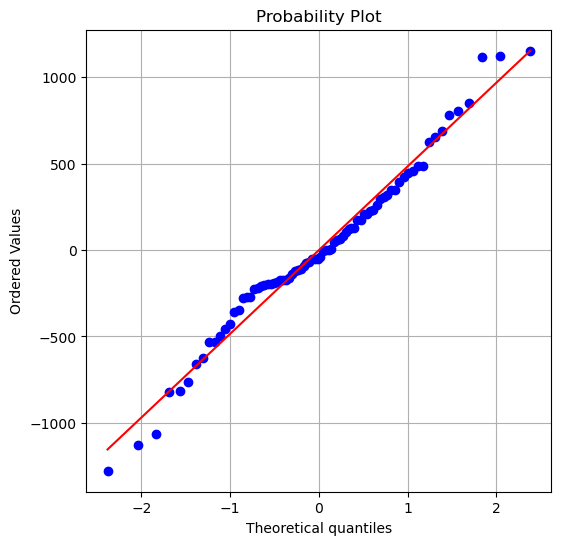

In [78]:
from scipy.stats import probplot 
fig, ax = plt.subplots(figsize=(6,6))
probplot(results.resid, plot=ax, fit=True) # the .resid attribute contains a numpy array of the residuals
plt.grid(True)

#### Linearity & Non-constant variance

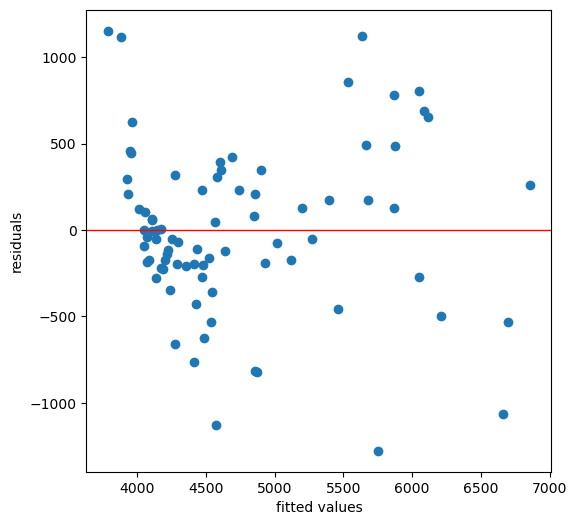

In [79]:
fig, ax = plt.subplots(figsize=(6,6))
plt.scatter(results.fittedvalues, results.resid)
ax.set_xlabel('fitted values')
ax.set_ylabel('residuals')
ax.axhline(linewidth=1, color='r')
plt.show()

**Task 3**: 
* Reproduce the plots above but for the model that used non-differenced data that you produced earlier
* What would you conclude from each of these plots? Does your fitted model satisfy all of the assumptions to mean it is trustworthy? 

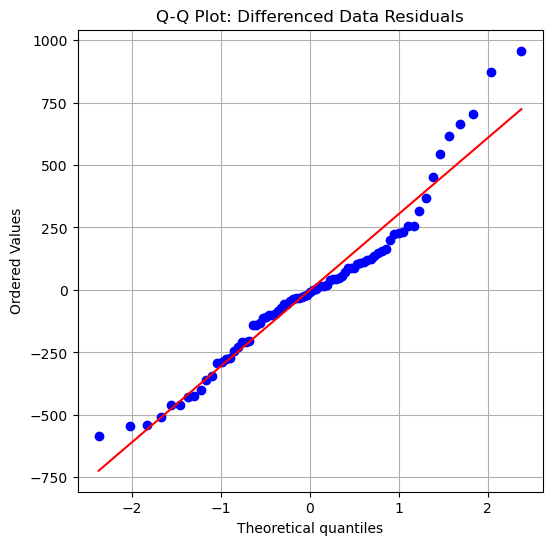

In [82]:
#### your solution here

fig, ax = plt.subplots(figsize=(6, 6))
probplot(results.resid, plot=ax, fit=True)
plt.grid(True)
plt.title('Q-Q Plot: Differenced Data Residuals')
plt.show()

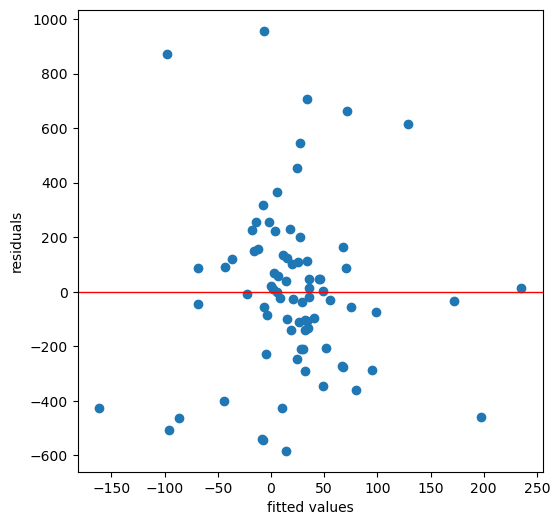

In [83]:
fig, ax = plt.subplots(figsize=(6,6))
plt.scatter(results.fittedvalues, results.resid)
ax.set_xlabel('fitted values')
ax.set_ylabel('residuals')
ax.axhline(linewidth=1, color='r')
plt.show()

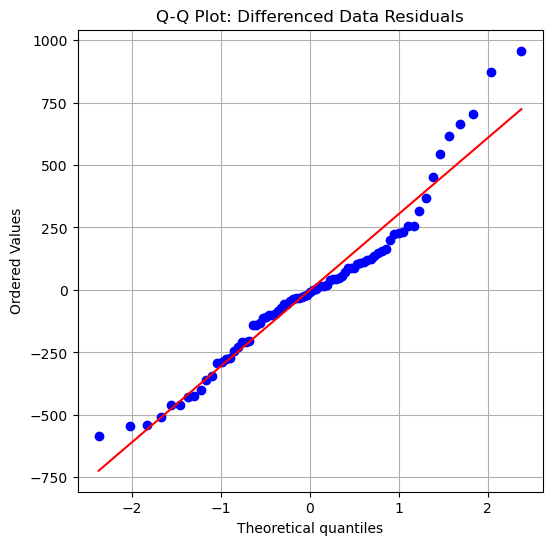

In [82]:
#### your solution here

fig, ax = plt.subplots(figsize=(6, 6))
probplot(results_diff.resid, plot=ax, fit=True)
plt.grid(True)
plt.title('Q-Q Plot: Differenced Data Residuals')
plt.show()

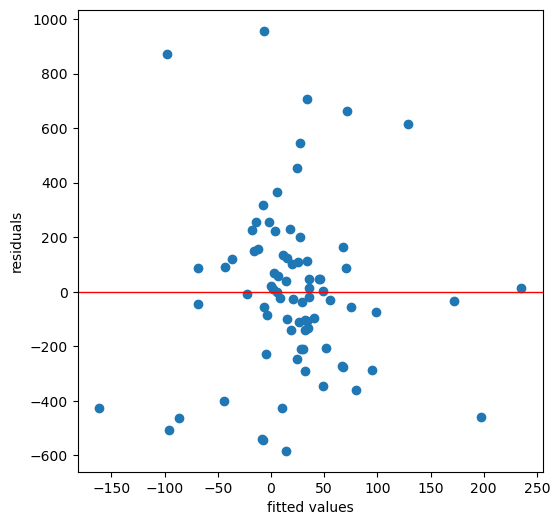

In [83]:
fig, ax = plt.subplots(figsize=(6,6))
plt.scatter(results_diff.fittedvalues, results_diff.resid)
ax.set_xlabel('fitted values')
ax.set_ylabel('residuals')
ax.axhline(linewidth=1, color='r')
plt.show()


<div style="border-left: 4px solid green; padding: 10px; background-color: #f0fff0;">
    
**Diagnostic Plot Analysis**
    
**Probability Plot (Non-differenced Data)**
**Conclusion:**
- Points follow the red line almost perfectly
- Excellent alignment across entire range
- **Normality: SATISFIED** ✓
- Residuals are normally distributed

---

**Q-Q Plot (Differenced Data)**
**Conclusion:**
- Points mostly follow the red line
- Slight deviation at the tails but acceptable
- **Normality: SATISFIED** ✓
- Residuals are approximately normally distributed

---

**Residuals vs Fitted Values (Non-differenced)**

**Conclusion:**
- **Homoscedasticity: VIOLATED** ✗
- Clear **fanning pattern**: variance increases with fitted values
- Residuals are larger on the right side
- This violates the assumption that errors have constant variance
- **Problem:** The model is less reliable at predicting higher DTOCS values

---

**Residuals vs Fitted Values (Differenced)**
**Conclusion:**
- **Homoscedasticity: MUCH BETTER** ✓ (mostly)
- Residuals are more evenly scattered around the line
- Less fanning pattern than non-differenced
- Variance is more consistent across fitted values
- Still not perfect, but significantly improved

---

**Overall Trustworthiness Assessment**

| Assumption | Non-differenced | Differenced |
|---|---|---|
| **Normality** | ✓ Good | ✓ Good |
| **Linearity** | ? (trend masks it) | ✓ Better |
| **Homoscedasticity** | ✗ VIOLATED | ✓ Better |
| **Independence** | ✗ VIOLATED (time series) | ✓ Better |

**Verdict**

**Non-differenced model: NOT TRUSTWORTHY**
- Violates homoscedasticity assumption (fanning pattern)
- Ignores time series structure (autocorrelation)
- High R² = 0.876 is misleading (mostly captures long-term trend)
- Slope and p-values may be unreliable

**Differenced model: MORE TRUSTWORTHY**
- Satisfies assumptions better
- Residuals are more evenly scattered
- Accounts for time series nature of data
- Lower R² is more honest (tests real short-term relationship)
- More conservative but more valid inference

**Recommendation:** Use the **differenced model** for statistical inference. The non-differenced model had inflated R² due to shared trends, not true predictive power.
</div>

## Variable selection

Usually we may have multiple measurements and we are unsure which are able to best explain the variable we are trying to predict. Then we use *multiple* linear regression to determine which variables are important.

For example we can consider the effect of advertising budgets for various media on overall sales of a product. See **ISLR** chapter 3. Here TV, Radio and Newspaper are individual advertising budgets and sales is the total numbers of a produce sold.

In [81]:
#### import advertising data
advertising = pd.read_csv('./Data/Advertising.csv', usecols=[1,2,3,4])
advertising.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


We can use statsmodels to fit a *multiple* linear regression model using the same code as before. It will take a 1-d array as the $Y$ variable, and a 2-d numpy matrix for the $X$ vars (where each column represents the data associated with $X1, X2, ...X_{p}$). 

**Note: we are now passing a pandas series (for $Y$, 1d), and a pandas dataframe(for $X$, 2d). This is much more convenient as statsmodels knows to use the series/dataframe titles as labels for our summary output.**

In [84]:
def perform_linear_regression(Y,X):
    """
    Function performs linear regression, prints adjusted r-squared and coef table, and returns the model results object.
    
    Input
    =====
    Y, pandas series,
    X, pandas dataframe,
    
    Return
    ======
    results, statsmodel linear regression results object
    
    """
    # fit multiple linear regression model
    X = sm.add_constant(X) # an intercept term to the model
    model = sm.OLS(Y, X)
    results = model.fit()
    # print results
    print('Adjusted R-squared: {0:1.3f}'.format(results.rsquared_adj))
    print(results.summary().tables[1])
    return(results)


sales = advertising['Sales']
media_budgets = advertising[['TV','Radio','Newspaper']]

results = perform_linear_regression(sales, media_budgets)

Adjusted R-squared: 0.896
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.9389      0.312      9.422      0.000       2.324       3.554
TV             0.0458      0.001     32.809      0.000       0.043       0.049
Radio          0.1885      0.009     21.893      0.000       0.172       0.206
Newspaper     -0.0010      0.006     -0.177      0.860      -0.013       0.011


In selecting a good model that only uses important media budget variables to explain the relationship of sales we would probably remove the Newspaper variable from our model (see chapter 3 for a detailed explantion of this). As you can see below the adjusted r-squared value is similar, and so we have not lost any information in our model. This was a good decision.

In [85]:
sales = advertising['Sales']
media_budgets = advertising[['TV','Radio']]

results = perform_linear_regression(sales, media_budgets)

Adjusted R-squared: 0.896
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.9211      0.294      9.919      0.000       2.340       3.502
TV             0.0458      0.001     32.909      0.000       0.043       0.048
Radio          0.1880      0.008     23.382      0.000       0.172       0.204


### Automating variable selection

Sometimes we have too many variables to manually check every possible combination of variables. The number of possible models quickly gets out of hand because there are $2^p$ models that contain subsets of $p$ variables. This means that even for moderate $p$, trying out every possible subset of the variables is infeasible. For instance, we saw that if $p = 2$, then
there are $2^2 = 4$ models to consider. But if $p = 30$, then we must consider $2^{30} = 1,073,741,824$ models!

One classical method for variable selection is *backward selection*. Here we start with all variables in the model, and backward remove the variable with the largest p-value — that is, the variable selection that is the least statistically significant. The new $(p − 1)$-variable model is fit, and the variable with the largest p-value is removed. This
procedure continues until a stopping rule is reached. For instance, we may stop when all remaining variables have a p-value below some threshold. (see **ISLR** section 3.2 'Two: deciding on important varaibles' for more info)

### Exercise 3: Finding alcohol content of wine using other characteristics

You will find a data set containing attributes of different types of wine in `wine.csv` in the data folder. Your task is to find which other variables are important in explaining the alcohol content.

You must:
* perform a linear regression using all the variables
* write a piece of code to implement backwards selection.

Your solution, at each stage of the selection, must:
* print the name of the variable removed
* print the adjusted r-squared
* return the coefficient and p-value results of each variable

You must use your code output to answer:
* How many variables have been removed to end with only significant variables?
* Which variables remain in your model?

HINT
* assume the stopping rule is that you stop when there are only significant varaibles contained in your model)


In [100]:
#### your solution here
wine = pd.read_csv('./Data/wine.csv')

print(wine.head())
print(f"Shape: {wine.shape}")
print(f"Columns: {wine.columns.tolist()}")


   Grape  Alcohol  Malic acid   Ash  Alcalinity of ash  Magnesium  \
0      1     1.51       -0.56  0.23              -1.17       1.91   
1      1     0.25       -0.50 -0.83              -2.48       0.02   
2      1     0.20        0.02  1.11              -0.27       0.09   
3      1     1.69       -0.35  0.49              -0.81       0.93   
4      1     0.29        0.23  1.84               0.45       1.28   

   Total phenols  Flavanoids  Nonflavanoid phenols  Proanthocyanins  \
0           0.81        1.03                 -0.66             1.22   
1           0.57        0.73                 -0.82            -0.54   
2           0.81        1.21                 -0.50             2.13   
3           2.48        1.46                 -0.98             1.03   
4           0.81        0.66                  0.23             0.40   

   Color intensity   Hue  OD280/OD315 of diluted wines  Proline  
0             0.25  0.36                          1.84     1.01  
1            -0.29  0.40  

In [101]:
X = wine.drop('Alcohol', axis=1)
y = wine['Alcohol']

print(f"Starting with {X.shape[1]} variables:")
print(X.columns.tolist())

Starting with 13 variables:
['Grape', 'Malic acid', 'Ash', 'Alcalinity of ash', 'Magnesium', 'Total phenols', 'Flavanoids', 'Nonflavanoid phenols', 'Proanthocyanins', 'Color intensity', 'Hue', 'OD280/OD315 of diluted wines', 'Proline']


In [102]:
X_const = sm.add_constant(X)
model = sm.OLS(y, X_const).fit()

print("INITIAL MODEL - ALL VARIABLES")
print(f"Adjusted R²: {model.rsquared_adj:.4f}\n")
print(model.summary())

INITIAL MODEL - ALL VARIABLES
Adjusted R²: 0.5870

                            OLS Regression Results                            
Dep. Variable:                Alcohol   R-squared:                       0.617
Model:                            OLS   Adj. R-squared:                  0.587
Method:                 Least Squares   F-statistic:                     20.36
Date:                Thu, 06 Aug 2026   Prob (F-statistic):           6.50e-28
Time:                        13:58:54   Log-Likelihood:                -166.50
No. Observations:                 178   AIC:                             361.0
Df Residuals:                     164   BIC:                             405.5
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------

In [103]:
iteration = 0
removed_variables = []

while True:
    # Fit model
    X_const = sm.add_constant(X)
    model = sm.OLS(y, X_const).fit()
    
    # Get p-values (skip intercept)
    pvalues = model.pvalues[1:]
    max_pvalue = pvalues.max() # big pvalue==too much noise
    max_var = pvalues.idxmax()
    
    print("=" * 80)
    print(f"ITERATION {iteration}")
    print("=" * 80)
    print(f"Adjusted R-squared: {model.rsquared_adj:.4f}\n")
    print(model.summary().tables[1])
    print()
    
    # Check stopping rule
    if max_pvalue > 0.05:
        print(f"🗑️ Removing: {max_var} (p-value = {max_pvalue:.4f})\n")
        removed_variables.append(max_var)
        X = X.drop(max_var, axis=1)
        iteration += 1
    else:
        print("✓ All variables significant (p < 0.05). DONE.\n")
        break

ITERATION 0
Adjusted R-squared: 0.5870

                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const                            1.1726      0.374      3.136      0.002       0.434       1.911
Grape                           -0.6052      0.191     -3.164      0.002      -0.983      -0.227
Malic acid                       0.1906      0.061      3.140      0.002       0.071       0.310
Ash                              0.0187      0.072      0.260      0.795      -0.123       0.160
Alcalinity of ash               -0.0649      0.077     -0.847      0.398      -0.216       0.086
Magnesium                       -0.0045      0.058     -0.079      0.937      -0.118       0.109
Total phenols                    0.0934      0.102      0.917      0.360      -0.108       0.294
Flavanoids                      -0.2152      0.147     -1.467      0.144      -0.505   

In [104]:
print("=" * 80)
print("FINAL RESULTS")
print("=" * 80)
print(f"Total variables removed: {len(removed_variables)}")
print(f"Variables removed: {removed_variables}\n")
print(f"Remaining variables: {X.columns.tolist()}\n")
print(f"Final Adjusted R²: {model.rsquared_adj:.4f}\n")

print("\nFINAL MODEL:")
print(model.summary())

FINAL RESULTS
Total variables removed: 8
Variables removed: ['Magnesium', 'OD280/OD315 of diluted wines', 'Ash', 'Hue', 'Nonflavanoid phenols', 'Total phenols', 'Flavanoids', 'Alcalinity of ash']

Remaining variables: ['Grape', 'Malic acid', 'Proanthocyanins', 'Color intensity', 'Proline']

Final Adjusted R²: 0.5964


FINAL MODEL:
                            OLS Regression Results                            
Dep. Variable:                Alcohol   R-squared:                       0.608
Model:                            OLS   Adj. R-squared:                  0.596
Method:                 Least Squares   F-statistic:                     53.32
Date:                Thu, 06 Aug 2026   Prob (F-statistic):           3.21e-33
Time:                        13:58:55   Log-Likelihood:                -168.69
No. Observations:                 178   AIC:                             349.4
Df Residuals:                     172   BIC:                             368.5
Df Model:                          

************************

**Task EXTRA (if you have time left and motivated)**

In-depth: OLS with linear algebra. In matrix form OLS is written as:


<div style="font-size: 120%;">  
Y = X β + ϵ 
</div>

The $β$ 's in this case are the same as the coefficients in the statsmodel. To get the $β$ array:

$$ β = (1 / (X^T X))  (X^T Y) $$


In [105]:
np.random.seed(25)
x = np.random.normal(size = 40)
y = 1.6*x + np.random.normal(size = 40)

In [106]:
### Your code here: use the numpy package for linear algebra / matrix operations


# Add intercept column (constant)
X = np.column_stack([np.ones(len(x)), x])

# Calculate β = (1/(X^T X))(X^T y)
# Which simplifies to: β = inv(X^T X) @ X^T @ y
beta = np.linalg.inv(X.T @ X) @ X.T @ y

print("Calculated coefficients using linear algebra:")
print(f"Intercept: {beta[0]:.4f}")
print(f"Slope: {beta[1]:.4f}")

# Verify with statsmodels
import statsmodels.api as sm
X_sm = sm.add_constant(x)
model = sm.OLS(y, X_sm).fit()
print("\nVerification with statsmodels:")
print(f"Intercept: {model.params[0]:.4f}")
print(f"Slope: {model.params[1]:.4f}")

print("\n✓ Both methods give the same result!")

Calculated coefficients using linear algebra:
Intercept: 0.0960
Slope: 1.4831

Verification with statsmodels:
Intercept: 0.0960
Slope: 1.4831

✓ Both methods give the same result!


**Task EXTRA** 

Understanding normality plot -- define method and code. Write your own code to plot normality of the residual

🌚 https://dodona.ugent.be/nl/activities/1859394339/#

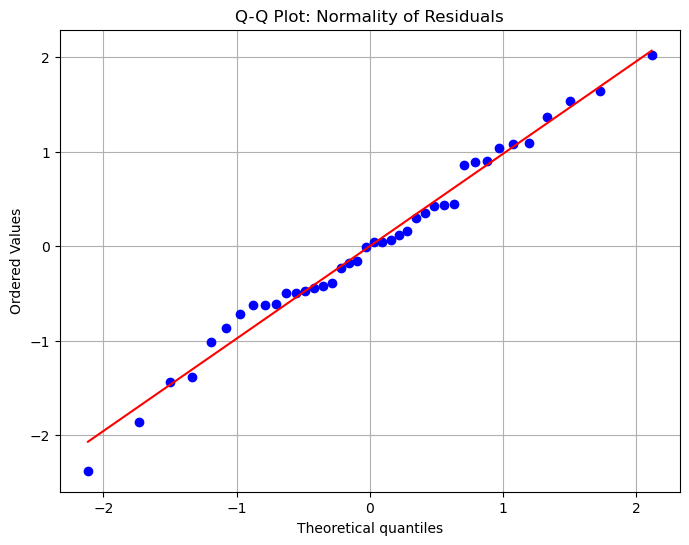

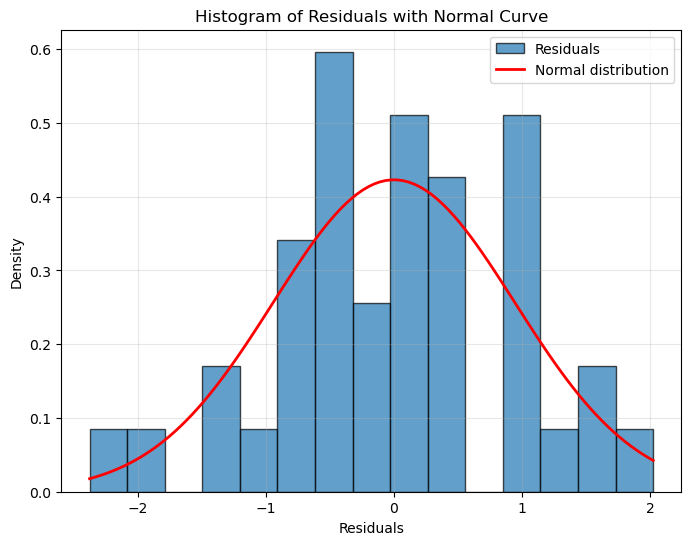

Shapiro-Wilk Test for Normality:
Test statistic: 0.9869
P-value: 0.9164
✓ Residuals appear to be normally distributed (p > 0.05)


In [107]:
### Your code here


# Using the model from previous task
residuals = model.resid

# Method 1: Q-Q Plot (quantile-quantile)
fig, ax = plt.subplots(figsize=(8, 6))
probplot(residuals, dist="norm", plot=ax)
ax.set_title("Q-Q Plot: Normality of Residuals")
ax.grid(True)
plt.show()

# Method 2: Histogram with normal curve overlay
fig, ax = plt.subplots(figsize=(8, 6))
ax.hist(residuals, bins=15, density=True, alpha=0.7, edgecolor='black', label='Residuals')

# Overlay normal distribution
mu, sigma = residuals.mean(), residuals.std()
x_range = np.linspace(residuals.min(), residuals.max(), 100)
ax.plot(x_range, (1/sigma/np.sqrt(2*np.pi))*np.exp(-(x_range-mu)**2/(2*sigma**2)), 
        'r-', linewidth=2, label='Normal distribution')

ax.set_xlabel('Residuals')
ax.set_ylabel('Density')
ax.set_title('Histogram of Residuals with Normal Curve')
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

# Check: Are residuals normal?
from scipy.stats import shapiro
stat, pvalue = shapiro(residuals)
print(f"Shapiro-Wilk Test for Normality:")
print(f"Test statistic: {stat:.4f}")
print(f"P-value: {pvalue:.4f}")
if pvalue > 0.05:
    print("✓ Residuals appear to be normally distributed (p > 0.05)")
else:
    print("✗ Residuals may not be normally distributed (p < 0.05)")

## To summarize

* Linear regression models the relationship between an output (dependent) variable Y and one or more input (independent) variables X using the following equation:
> **Y= β0 ​+ β1*​X1 ​+ β2*​X2 ​+ ... + βp*​Xp ​+ ϵ**

* β0​, β1​, …, βp​ are the regression **coefficients**, representing the estimated effect of each predictor on Y. These are the parameters we aim to estimate.

* ϵ is the **error term**, capturing the variability in Y not explained by the model.

* **R²** measures the proportion of variance in Y that is explained by the predictors X. It ranges from 0 to 1, where higher values indicate a better fit.

* The **p-values** give the significance of predictors (null hypothesis: coefficient = 0).

* Key **assumptions** of linear regression include:
> 1. Linearity: The relationship between X and Y is linear.
> 2. Independence of errors: Residuals are uncorrelated.
> 3. Homoscedasticity: Residuals have constant variance across all levels of X.
> 4. Normality of residuals: Residuals are approximately normally distributed.
> 5. No multicollinearity: Predictors are not highly correlated with each other.

These assumptions are typically verified using **residual plots** and statistical tests to ensure the validity and reliability of the regression model.

* In Python, several libraries can perform linear regression. **statsmodels** is particularly useful for obtaining detailed results, including R² and adjusted R², coefficients and their statistical significance (p-values), and diagnostics for checking model assumptions.

* To avoid overfitting, it is important to retain only predictors that have a significant impact on Y. Methods like **backward selection** (iteratively removing the least significant predictors) can help achieve a parsimonious model.

* Linear regression is both used with a classical statistical approach (understanding and quantifying the relationship between Y and X) and Machine Learning approach (focuses on accurate prediction of Y)